
# RFM Feature Engineering

## Project Overview

### Objective

The objective of this notebook is to calculate customer-level RFM (Recency, Frequency, Monetary) metrics using delivered order transactions.

These metrics will provide the foundation for customer segmentation in the next stage of the project.

### RFM Definitions

- **Recency:** Number of days since the customer's most recent delivered order.
- **Frequency:** Total number of delivered orders placed by the customer.
- **Monetary:** Total delivered order value after deducting successful refunds.

### Analysis Reference Date

June 15, 2026

All RFM metrics will be calculated relative to this snapshot date.


### Setting up the imports and database connections

In [1]:
import sys
from pathlib import Path

# Add project root to Python's import path
project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))

import pandas as pd
from sqlalchemy import text

import numpy as np

from src.db import engine, test_connection

test_connection()

('neondb', 'ecom', 'PostgreSQL 18.7 (84da7d8) on aarch64-unknown-linux-gnu, compiled by gcc (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0, 64-bit')

In [2]:
query="""
select count(*) from ecom.orders
""" 

orders_check_df = pd.read_sql(text(query), engine)
orders_check_df

,count
0,40000


## RFM Data Extraction

### Define the Snapshot Date

The analysis snapshot date is **June 15, 2026**.

The latest delivered order in the dataset was recorded on June 14, 2026. Therefore, June 15 is used as the reference date for calculating customer Recency.



In [3]:
snapshot_date = pd.Timestamp("2026-06-15").date()
print("RFM Snapshot Date:", snapshot_date)

RFM Snapshot Date: 2026-06-15



### Consolidated Customer-Level RFM Extraction

A single SQL query is used to calculate customer-level order metrics and successful refunds.

Common Table Expressions (CTEs) aggregate delivered orders and successful refunds separately. The results are joined at the customer level to calculate Net Monetary.

This approach avoids multiple database queries for the individual RFM components.


In [4]:
query = """
WITH order_metrics AS (
    SELECT
        customer_id,
        MAX(created_at)::date AS last_purchase_date,
        COUNT(*) AS frequency,
        SUM(total) AS gross_monetary
    FROM ecom.orders
    WHERE LOWER(TRIM(status)) = 'delivered'
    GROUP BY customer_id
),

refund_metrics AS (
    SELECT
        o.customer_id,
        SUM(r.amount) AS successful_refunds
    FROM ecom.refunds r
    INNER JOIN ecom.orders o
        ON r.order_id = o.order_id
    WHERE LOWER(TRIM(r.status)) = 'succeeded'
    GROUP BY o.customer_id
)

SELECT
    o.customer_id,
    o.last_purchase_date,
    CAST(:snapshot_date AS date) - o.last_purchase_date AS recency,
    o.frequency,
    o.gross_monetary,
    COALESCE(r.successful_refunds, 0) AS successful_refunds,
    o.gross_monetary - COALESCE(r.successful_refunds, 0)
        AS net_monetary
FROM order_metrics o
LEFT JOIN refund_metrics r
    ON o.customer_id = r.customer_id
ORDER BY o.customer_id;
"""

rfm_sql_df = pd.read_sql(
    text(query),
    engine,
    params={'snapshot_date': snapshot_date}
)
print("Shape:", rfm_sql_df.shape)
rfm_sql_df.head()

Shape: (6052, 7)


,customer_id,last_purchase_date,recency,frequency,gross_monetary,successful_refunds,net_monetary
0,1,2026-05-25,21,4,78694.94,0.0,78694.94
1,2,2026-05-07,39,1,3181.28,0.0,3181.28
2,4,2026-05-27,19,3,26601.92,0.0,26601.92
3,7,2026-05-09,37,1,1010.82,0.0,1010.82
4,9,2026-04-26,50,2,4302.28,0.0,4302.28



## Initial Data Validation

### Dataset Dimensions and Customer Uniqueness

Before proceeding with RFM analysis, verify the dimensions of the extracted dataset and ensure that each customer appears only once.
Since the data is aggregated at the customer level, each customer_id should be unique.


In [5]:
print("Dataset shape:", rfm_sql_df.shape)
print("Unique customers:", rfm_sql_df['customer_id'].nunique())
print("Duplicate customer IDs:", rfm_sql_df['customer_id'].duplicated().sum())
rfm_sql_df.isna().sum()

Dataset shape: (6052, 7)
Unique customers: 6052
Duplicate customer IDs: 0


customer_id           0
last_purchase_date    0
recency               0
frequency             0
gross_monetary        0
successful_refunds    0
net_monetary          0
dtype: int64


### Financial Reconciliation

Verify the relationship between Gross Monetary, Successful Refunds, and Net Monetary.

Net Monetary should equal Gross Monetary minus successful refunds.

The aggregate totals are also compared against the previously established project results to ensure consistency.


In [6]:
gross_monetary = rfm_sql_df['gross_monetary'].sum()
successful_refunds = rfm_sql_df['successful_refunds'].sum()
net_monetary = rfm_sql_df['net_monetary'].sum()

print(f"Gross Monetary: ₹{gross_monetary:,.2f}")
print(f"Successful Refunds: ₹{successful_refunds:,.2f}")
print(f"Net Monetary: ₹{net_monetary:,.2f}")

print(
    "\nFinancial reconciliation:",
    round(gross_monetary - successful_refunds, 2)
    == round(net_monetary, 2)
)

Gross Monetary: ₹150,418,237.66
Successful Refunds: ₹1,058,291.82
Net Monetary: ₹149,359,945.84

Financial reconciliation: True



##  Final RFM Dataset

### Create the Customer-Level RFM DataFrame

The extracted dataset contains additional intermediate columns used for financial reconciliation.

For customer segmentation, retain only customer_id, Recency, Frequency, and Net Monetary.

Rename `net_monetary` to `monetary` to establish the final RFM dataset structure.


In [7]:
rfm_df = (
    rfm_sql_df[
        ['customer_id', 'recency', 'frequency', 'net_monetary']
    ]
    .rename(columns={'net_monetary': 'monetary'})
    .copy()
)

print("Shape:", rfm_df.shape)
print("Columns:", rfm_df.columns.tolist())

rfm_df.head()

Shape: (6052, 4)
Columns: ['customer_id', 'recency', 'frequency', 'monetary']


,customer_id,recency,frequency,monetary
0,1,21,4,78694.94
1,2,39,1,3181.28
2,4,19,3,26601.92
3,7,37,1,1010.82
4,9,50,2,4302.28



### RFM Metric Validation

Validate the final RFM dataset to ensure that the calculated metrics contain valid values.

- Recency should be zero or greater.
- Frequency should be greater than zero.
- Monetary should be zero or greater.


In [8]:
print("Negative Recency:", (rfm_df['recency'] < 0).sum())
print("Zero or negative Frequency:", (rfm_df['frequency'] <= 0).sum())
print("Negative Monetary:", (rfm_df['monetary'] < 0).sum())
print("Zero Monetary:", (rfm_df['monetary'] == 0).sum())

Negative Recency: 0
Zero or negative Frequency: 0
Negative Monetary: 0
Zero Monetary: 17



## RFM Distribution Analysis

### Descriptive Statistics

Calculate summary statistics for Recency, Frequency, and Monetary to understand their distributions, central tendencies, variability, and ranges.

These statistics will help identify skewness and potential outliers before visualising the distributions.


In [9]:
rfm_df[['recency', 'frequency', 'monetary']].describe().T

,count,mean,std,min,25%,50%,75%,max
recency,6052.0,41.057336,25.480830,1.0,19.00,39.00,64.000,91.00
frequency,6052.0,3.301223,5.768117,1.0,1.00,1.00,4.000,102.00
monetary,6052.0,24679.435863,46884.823779,0.0,4184.28,11326.82,28085.885,787135.98



### Distribution Observations

The descriptive statistics indicate substantial right-skewness in Frequency and Monetary.

- Frequency has a median of 1 order, compared with a mean of 3.30 orders.
- Monetary has a median of ₹11,326.82, compared with a mean of ₹24,679.44.
- Recency has a mean of 41.06 days and a median of 39 days.

These differences suggest that a relatively small group of customers has higher purchase frequency and spending.

Histograms will be used to examine the shape of each distribution and identify potential extreme values.



### Recency Bands and Customer Share




In [10]:
recency_bands = pd.cut(
    rfm_df['recency'],
    bins=[0, 30, 60, 91],
    labels=['1–30 days', '31–60 days', '61–91 days']
)

recency_summary = (
    recency_bands
    .value_counts(sort=False)
    .to_frame(name='customers')
)

recency_summary['customer_share_pct'] = (
    recency_summary['customers'] / len(rfm_df) * 100
)

recency_summary.round(2)

,customers,customer_share_pct
recency,,
1–30 days,2532,41.84
31–60 days,1753,28.97
61–91 days,1767,29.20



### Frequency Bands and Order Contribution

Group customers by their number of delivered orders to understand the distribution of purchase frequency.

For each frequency band, calculate:
- Number of customers
- Percentage of the customer base
- Total delivered orders
- Percentage contribution to all delivered orders


In [11]:
frequency_bands = pd.cut(
    rfm_df['frequency'],
    bins=[0, 1, 5, 10, float('inf')],
    labels=['1 order', '2–5 orders', '6–10 orders', 'More than 10 orders']
)

frequency_summary = (
    rfm_df.assign(frequency_band=frequency_bands)
    .groupby('frequency_band', observed=False)
    .agg(
        customers=('customer_id', 'count'),
        total_orders=('frequency', 'sum')
    )
)

frequency_summary['customer_share_pct'] = (
    frequency_summary['customers'] / len(rfm_df) * 100
)

frequency_summary['order_contribution_pct'] = (
    frequency_summary['total_orders']
    / rfm_df['frequency'].sum() * 100
)

frequency_summary.round(2)

,customers,total_orders,customer_share_pct,order_contribution_pct
frequency_band,,,,
1 order,3034,3034,50.13,15.19
2–5 orders,2231,7166,36.86,35.87
6–10 orders,527,3829,8.71,19.17
More than 10 orders,260,5950,4.30,29.78


In [12]:
rfm_df[['recency', 'frequency', 'monetary']].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95]
).T

,count,mean,std,min,25%,50%,75%,90%,95%,max
recency,6052.0,41.057336,25.480830,1.0,19.00,39.00,64.000,76.900,84.000,91.00
frequency,6052.0,3.301223,5.768117,1.0,1.00,1.00,4.000,6.000,10.000,102.00
monetary,6052.0,24679.435863,46884.823779,0.0,4184.28,11326.82,28085.885,54913.736,81412.834,787135.98


### Customer Revenue Concentration

Customer revenue concentration analysis examines how much net delivered revenue is contributed by the highest-spending customers.

In [13]:
total_customers = len(rfm_df)
total_revenue = rfm_df['monetary'].sum()

customer_groups = {
    'Top 10%': round(total_customers * 0.10),
    'Top 20%': round(total_customers * 0.20),
    'Top 50%': round(total_customers * 0.50)
}

ranked_customers = rfm_df.sort_values(
    'monetary',
    ascending=False
).reset_index(drop=True)

for group, count in customer_groups.items():
    revenue = ranked_customers.head(count)['monetary'].sum()
    print(
        f"{group} ({count} customers): "
        f"₹{revenue:,.2f} | "
        f"{revenue / total_revenue * 100:.2f}%"
    )

bottom_50_revenue = ranked_customers.tail(
    customer_groups['Top 50%']
)['monetary'].sum()

print(
    f"Bottom 50%: ₹{bottom_50_revenue:,.2f} | "
    f"{bottom_50_revenue / total_revenue * 100:.2f}%"
)

Top 10% (605 customers): ₹71,705,560.81 | 48.01%
Top 20% (1210 customers): ₹97,534,202.11 | 65.30%
Top 50% (3026 customers): ₹135,208,067.78 | 90.52%
Bottom 50%: ₹14,151,878.06 | 9.48%


The findings indicate that net revenue is concentrated among a relatively small proportion of customers. The top 20% contribute approximately 65.30% of net delivered revenue, while the bottom 50% contribute only 9.48%.

Business implication: Maintaining relationships with high-value customers is important for protecting revenue. Lower-spending customers may represent an opportunity for growth through targeted engagement and repeat-purchase initiatives.


### Distribution Visualisation

Histograms are used to examine the frequency distributions of Recency, Frequency, and Monetary.

Separate plots are created for each metric to understand customer behaviour and identify skewness and extreme observations.


#### Recency Distribution

Examine the distribution of days since customers' last delivered purchase.

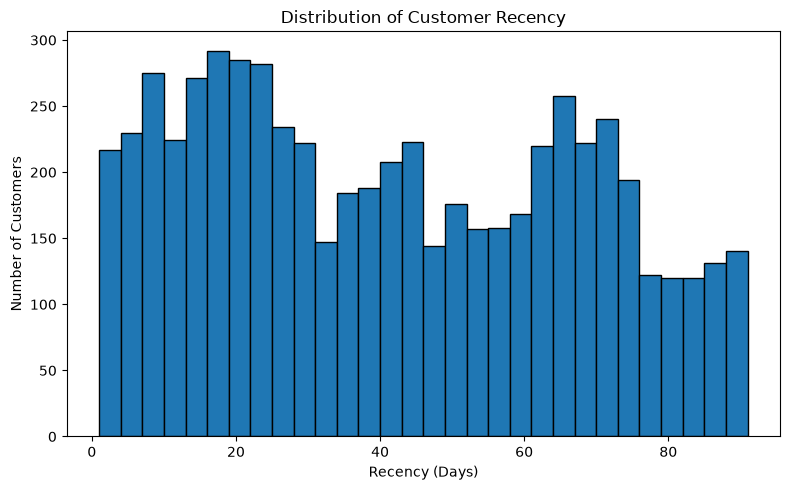

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(rfm_df['recency'], bins=30, edgecolor='black')

plt.title('Distribution of Customer Recency')
plt.xlabel('Recency (Days)')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.show()


**Observation:**

The Recency distribution shows an uneven pattern, with higher customer concentrations around 15–25 days and 65–75 days.

This indicates variation in how recently customers have made purchases. Customers with higher Recency values may require re-engagement efforts to encourage repeat purchases.

The distribution does not indicate a clear isolated extreme-value cluster.



#### Frequency Distribution

Examine the distribution of delivered orders per customer to understand customer purchase frequency.


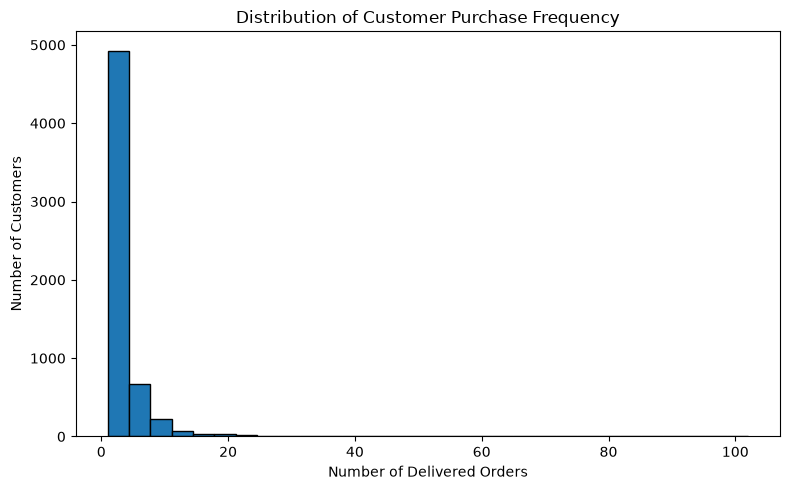

In [15]:
plt.figure(figsize=(8, 5))
plt.hist(rfm_df['frequency'], bins=30, edgecolor='black')

plt.title('Distribution of Customer Purchase Frequency')
plt.xlabel('Number of Delivered Orders')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.show()

### Frequency — Full distribution (log scale)
First, improve the histogram by using integer-width bins. Frequency is a discrete count, so this is more appropriate than 30 arbitrary bins.

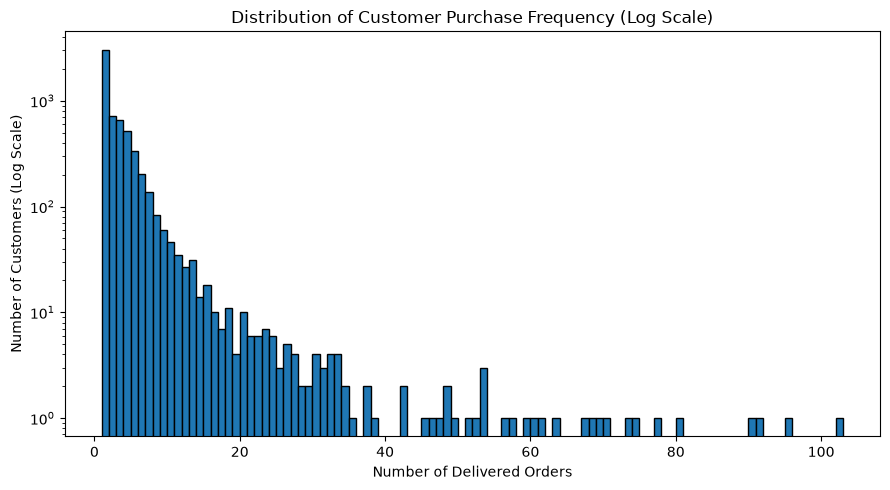

In [16]:
plt.figure(figsize=(9, 5))
bins = range(1, rfm_df['frequency'].max() + 2)
plt.hist(
    rfm_df['frequency'],
    bins=bins,
    edgecolor='black'
)
plt.yscale('log')

plt.title('Distribution of Customer Purchase Frequency (Log Scale)')
plt.xlabel('Number of Delivered Orders')
plt.ylabel('Number of Customers (Log Scale)')
plt.tight_layout()
plt.show()


#### Frequency Distribution — Zoomed View

A zoomed view is used to examine the distribution among customers with up to 20 delivered orders.

This provides greater visibility into the purchase frequency of the majority of customers while retaining the full distribution for reference.


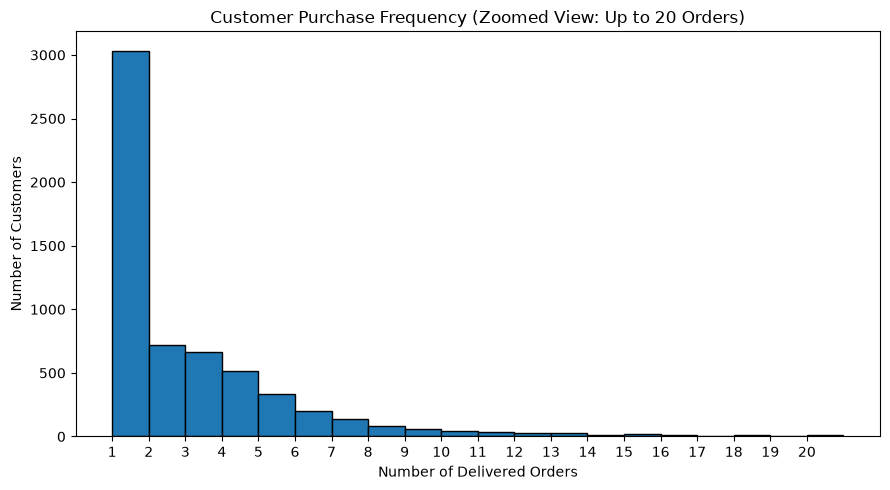

In [17]:
frequency_zoom = rfm_df[rfm_df['frequency'] <= 20]

plt.figure(figsize=(9, 5))

bins = range(1, 22)

plt.hist(
    frequency_zoom['frequency'],
    bins=bins,
    edgecolor='black'
)

plt.title('Customer Purchase Frequency (Zoomed View: Up to 20 Orders)')
plt.xlabel('Number of Delivered Orders')
plt.ylabel('Number of Customers')
plt.xticks(range(1, 21))
plt.tight_layout()
plt.show()

Zooming in the histogram



**Observation:**

The Frequency distribution is highly right-skewed, with a large concentration of customers having only one delivered order. Customer counts decline substantially as purchase frequency increases, indicating that repeat purchasing is relatively limited across the customer base.

The full distribution, displayed using a logarithmic Y-axis, reveals a long tail of customers with higher purchase frequencies. The zoomed view (up to 20 orders) provides better visibility into the purchasing patterns of the majority of customers.

The maximum frequency of 102 orders was investigated separately and confirmed to be legitimate. Therefore, no customers were removed based solely on high purchase frequency.

The zoomed view is used only for visualisation; the complete dataset is retained for subsequent analysis and segmentation.



#### Monetary Distribution

Examine the distribution of customers' net spending after deducting successful refunds.

A full distribution and a zoomed view will be used to understand spending patterns and the presence of high-value customers.


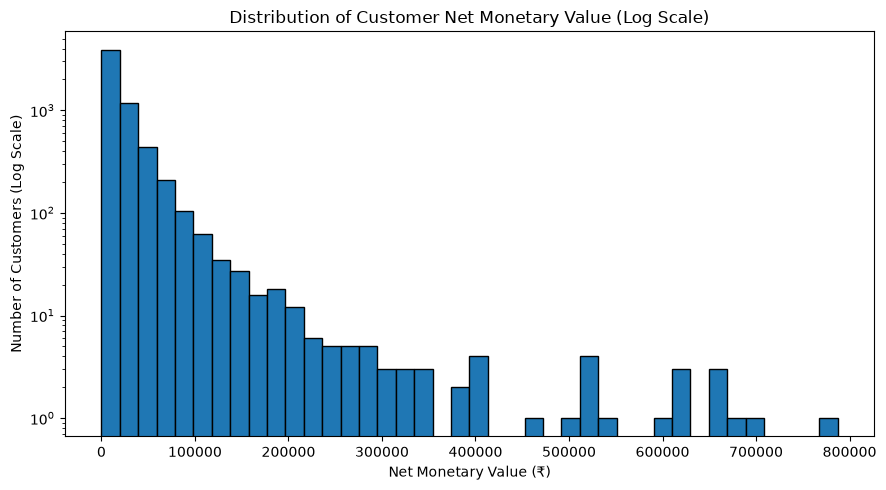

In [18]:
plt.figure(figsize=(9, 5))

plt.hist(
    rfm_df['monetary'],
    bins=40,
    edgecolor='black'
)

plt.yscale('log')

plt.title('Distribution of Customer Net Monetary Value (Log Scale)')
plt.xlabel('Net Monetary Value (₹)')
plt.ylabel('Number of Customers (Log Scale)')
plt.ticklabel_format(style='plain', axis='x')
plt.tight_layout()
plt.show()


**Observation:**

The Net Monetary distribution is highly right-skewed, with a large concentration of customers at lower spending levels and progressively fewer customers at higher spending levels.

The logarithmic Y-axis makes the long tail and relatively infrequent high-spending observations more visible.

The maximum Net Monetary value of ₹787,135.98 indicates substantial variation in customer spending. These high-value customers should be investigated and retained in the analysis rather than automatically treated as invalid outliers.



#### Monetary Distribution — Zoomed View

A zoomed histogram is used to examine customers with Net Monetary values up to ₹100,000.

This view provides greater visibility into the spending distribution among the majority of customers, while the full distribution retains the high-value customer observations.


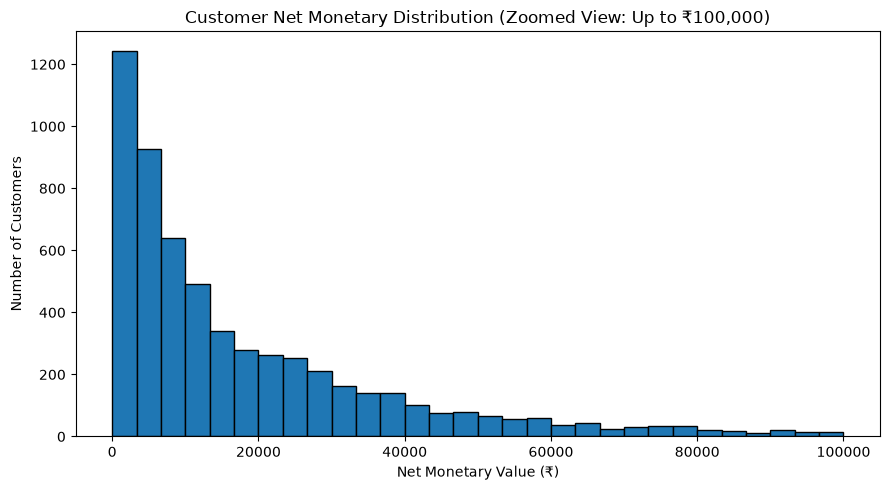

In [19]:
monetary_zoom = rfm_df[rfm_df['monetary'] <= 100000]

plt.figure(figsize=(9, 5))

plt.hist(
    monetary_zoom['monetary'],
    bins=30,
    edgecolor='black'
)

plt.title('Customer Net Monetary Distribution (Zoomed View: Up to ₹100,000)')
plt.xlabel('Net Monetary Value (₹)')
plt.ylabel('Number of Customers')
plt.ticklabel_format(style='plain', axis='x')
plt.tight_layout()
plt.show()


**Observation:**

The zoomed Net Monetary distribution shows that most customers have relatively low spending, with the highest concentration in the lower spending ranges.

Customer counts decline progressively as Net Monetary increases, indicating a right-skewed spending distribution.

Although the zoomed view focuses on customers with Net Monetary values up to ₹100,000, the complete dataset retains all high-spending customers. The zoomed view is used only to improve visual interpretation and does not involve excluding customers from the analysis.



## Customer Spending Analysis

### Identify the Top 10% of Customers by Net Monetary

Customers are ranked by Net Monetary value to identify the highest-spending 10% of the customer base.

This analysis compares the spending contribution and purchasing behaviour of the top 10% against the remaining 90% of customers.

Net Monetary is used for ranking because it accounts for successful refunds.


In [20]:
# Identify the top 10% of customers by Net Monetary
top_10_count = round(len(rfm_df) * 0.10)

top_10_customers = (
    rfm_df.nlargest(top_10_count, 'monetary')
    .copy()
)

remaining_customers = (
    rfm_df[
        ~rfm_df['customer_id'].isin(top_10_customers['customer_id'])
    ]
    .copy()
)

print("Total customers:", len(rfm_df))
print("Top 10% customers:", len(top_10_customers))
print("Remaining customers:", len(remaining_customers))

Total customers: 6052
Top 10% customers: 605
Remaining customers: 5447



### Compare Customer Spending and Purchasing Behaviour

Compare the top 10% of customers with the remaining 90% to understand differences in spending contribution and purchase behaviour.

The comparison includes total Net Monetary, average spending per customer, average purchase frequency, and average Net Order Value.

Average Net Order Value is calculated as total Net Monetary divided by total delivered orders within each group.


In [21]:
def calculate_group_metrics(group):
    return pd.Series({
        'customers': len(group),
        'total_net_monetary': group['monetary'].sum(),
        'avg_net_spending_per_customer': group['monetary'].mean(),
        'avg_frequency_per_customer': group['frequency'].mean(),
        'avg_net_order_value': (
            group['monetary'].sum() / group['frequency'].sum()
        )
    })


group_comparison = pd.DataFrame({
    'Top 10%': calculate_group_metrics(top_10_customers),
    'Remaining 90%': calculate_group_metrics(remaining_customers)
})

group_comparison.round(2)

,Top 10%,Remaining 90%
customers,605.00,5447.00
total_net_monetary,71705560.81,77654385.03
avg_net_spending_per_customer,118521.59,14256.36
avg_frequency_per_customer,13.09,2.21
avg_net_order_value,9054.88,6439.00


### Obesrvations
Although the top 10% represents only 10% of customers, they contribute approximately 48.01% of total Net Monetary.
The top 10% purchase approximately 5.92 times more frequently.
The top 10% also have approximately 40.63% higher average Net Order Value.

### Business interpretation
The highest-spending customers generate substantially more spending through two factors:
- They purchase more frequently.
- They spend more per order on average.
This suggests that their higher contribution is not driven by purchase frequency alone.


### Net Monetary Contribution by Customer Group

Calculate the percentage contribution of each customer group to total Net Monetary.

This helps quantify the relative importance of the top 10% of customers to overall customer spending.


In [22]:
total_net_monetary = rfm_df['monetary'].sum()

group_comparison.loc['net_monetary_contribution_pct'] = (
    group_comparison.loc['total_net_monetary']
    / total_net_monetary * 100
)

group_comparison.round(2)

,Top 10%,Remaining 90%
customers,605.00,5447.00
total_net_monetary,71705560.81,77654385.03
avg_net_spending_per_customer,118521.59,14256.36
avg_frequency_per_customer,13.09,2.21
avg_net_order_value,9054.88,6439.00
net_monetary_contribution_pct,48.01,51.99



### Key Findings and Business Implications

**Key Findings**

1. **High spending concentration:** The top 10% of customers contribute 48.01% of total Net Monetary, despite representing only 10% of the customer base.

2. **Higher purchase frequency:** The top 10% average 13.09 delivered orders per customer, compared with 2.21 among the remaining 90%. This represents approximately 5.92 times higher purchase frequency.

3. **Higher order value:** The top 10% have an average Net Order Value of ₹9,054.88, approximately 40.63% higher than the remaining 90% (₹6,439.00).

4. **Higher customer spending:** Average Net Monetary per customer is ₹1,18,521.59 for the top 10%, compared with ₹14,256.36 for the remaining 90%.

**Business Implications**

- **Retain high-value customers:** Prioritise customer retention through loyalty programmes, personalised offers, and exclusive benefits.
- **Encourage repeat purchases:** Develop targeted campaigns to convert one-time and low-frequency customers into repeat purchasers.
- **Increase order value:** Use relevant cross-selling and upselling strategies to encourage higher spending per order.

The analysis indicates that high-value customers generate greater spending through both higher purchase frequency and higher average order value.
